# Sentinel-2 L2A download with Element 84 Earth Search

**Hackathon starter notebook** — search and download Sentinel-2 Level-2A scenes from the public AWS catalog indexed by [Element 84 Earth Search](https://earth-search.aws.element84.com/v1).

### What you will learn
1. How [STAC](https://stacspec.org/en/about/) search works (bbox + dates + cloud cover)
2. How to list matching scenes
3. How to download selected bands as Cloud-Optimized GeoTIFFs (COGs)
4. How to open and plot a quick RGB preview

### Why Element 84 (not CDSE) for this use case?
| | Earth Search (Element 84) | CDSE (Copernicus Data Space) |
|---|---|---|
| Account | Not required | Free account + OAuth |
| Format | Per-band COGs | Full `.SAFE` ZIP packages |
| Best for | Hackathons, AOI + a few bands | Official full products |

> **Tip:** Start small (tiny AOI, short date range, low cloud %). Full Poland × all bands is terabytes of data!

### Prerequisites
- Python 3.10+
- Internet access
- No AWS or CDSE credentials needed for this notebook


## 0. Install dependencies

Run once per environment. Restart the kernel if imports fail after install.

- pystac-client>=0.8
- rasterio>=1.3
- matplotlib>=3.8
- pandas>=2.0
- tqdm>=4.66
- pyproj>=3.6


## 1. Imports and public-read settings

Earth Search points at **public** AWS Open Data buckets. Setting `AWS_NO_SIGN_REQUEST` lets GDAL/rasterio read COGs without credentials.


In [1]:
import os
from pathlib import Path

# Must be set BEFORE importing rasterio
os.environ["AWS_NO_SIGN_REQUEST"] = "YES"
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from pystac_client import Client
from rasterio.windows import from_bounds

print("Imports OK")


Imports OK


## 2. Configure your search (edit this cell)

Default AOI is a **small** box near Poznań, Poland (~one tile, manageable downloads).

**Student task:** change `BBOX`, dates, and `MAX_CLOUD` to your own study area.


In [2]:
# --- EDIT ME ---------------------------------------------------------------
STAC_URL = "https://earth-search.aws.element84.com/v1"
COLLECTION = "sentinel-2-l2a"  # surface reflectance (atmospherically corrected)

# [min_lon, min_lat, max_lon, max_lat]  — WGS84
BBOX = [17.66, 50.34, 17.76, 50.40]  # small area south of Poland

START_DATE = "2025-06-01"
END_DATE = "2025-06-30"
MAX_CLOUD = 40  # percent

# Which bands to download (friendly names used by Earth Search)
# Common: blue, green, red, nir, rededge1, swir16, scl
BANDS = ["red", "green", "blue", "nir", "scl"]

# How many scenes to download in the demo (search can return more)
MAX_DOWNLOADS = 1

OUT_DIR = Path("/your-directory/sentinel2_l2a")
# ---------------------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUT_DIR.resolve()}")
print(f"AOI bbox: {BBOX}")
print(f"Dates: {START_DATE} → {END_DATE}, cloud < {MAX_CLOUD}%")


Output directory: /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a
AOI bbox: [17.66, 50.34, 17.76, 50.4]
Dates: 2025-06-01 → 2025-06-30, cloud < 40%


## 3. Search the catalog

STAC (SpatioTemporal Asset Catalog) lets you query *where / when / which collection* without downloading pixels yet.


In [3]:
catalog = Client.open(STAC_URL)

search = catalog.search(
    collections=[COLLECTION],
    bbox=BBOX,
    datetime=f"{START_DATE}/{END_DATE}",
    query={"eo:cloud_cover": {"lt": MAX_CLOUD}},
)

items = list(search.items())
print(f"Found {len(items)} scenes")

if not items:
    raise SystemExit(
        "No scenes found. Widen the date range, increase MAX_CLOUD, or enlarge BBOX."
    )


Found 7 scenes


## 4. Inspect results as a table

Useful columns before you spend bandwidth downloading.


In [4]:
rows = []
for item in items:
    rows.append(
        {
            "id": item.id,
            "datetime": item.datetime.isoformat() if item.datetime else None,
            "cloud_%": round(item.properties.get("eo:cloud_cover", float("nan")), 2),
            "platform": item.properties.get("platform"),
            "mgrs_tile": item.properties.get("grid:code") or item.properties.get("s2:mgrs_tile"),
            "n_assets": len(item.assets),
        }
    )

results = pd.DataFrame(rows).sort_values(["cloud_%", "datetime"])
results


,id,datetime,cloud_%,platform,mgrs_tile,n_assets
1,S2B_33UXR_20250630_0_L2A,2025-06-30T09:56:52.892000+00:00,0.01,sentinel-2b,MGRS-33UXR,38
0,S2A_33UXR_20250630_1_L2A,2025-06-30T10:07:03.911000+00:00,0.01,sentinel-2a,MGRS-33UXR,38
5,S2C_33UXR_20250615_0_L2A,2025-06-15T09:57:09.361000+00:00,0.02,sentinel-2c,MGRS-33UXR,38
6,S2B_33UXR_20250613_0_L2A,2025-06-13T10:06:44.998000+00:00,0.07,sentinel-2b,MGRS-33UXR,38
2,S2C_33UXR_20250628_0_L2A,2025-06-28T10:07:07.891000+00:00,23.84,sentinel-2c,MGRS-33UXR,38
3,S2A_33UXR_20250620_0_L2A,2025-06-20T10:07:00.355000+00:00,35.34,sentinel-2a,MGRS-33UXR,38
4,S2B_33UXR_20250620_1_L2A,2025-06-20T09:56:50.813000+00:00,35.89,sentinel-2b,MGRS-33UXR,38


## 5. Peek at available assets for one scene

Each STAC **item** is one scene. **Assets** are downloadable files (usually one COG per band).


In [6]:
example = items[0]
print("Scene:", example.id)
print("Assets:")
for name, asset in sorted(example.assets.items()):
    print(f"  {name:20s}  {asset.media_type or ''}  {asset.href[:80]}...")


Scene: S2A_33UXR_20250630_1_L2A
Assets:
  aot                   image/tiff; application=geotiff; profile=cloud-optimized  https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/33/U/XR/20...
  aot-jp2               image/jp2  s3://sentinel-s2-l2a/tiles/33/U/XR/2025/6/30/1/R20m/AOT.jp2...
  blue                  image/tiff; application=geotiff; profile=cloud-optimized  https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/33/U/XR/20...
  blue-jp2              image/jp2  s3://sentinel-s2-l2a/tiles/33/U/XR/2025/6/30/1/R10m/B02.jp2...
  cloud                 image/jp2  s3://sentinel-s2-l2a/tiles/33/U/XR/2025/6/30/1/qi/CLD_20m.jp2...
  coastal               image/tiff; application=geotiff; profile=cloud-optimized  https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/33/U/XR/20...
  coastal-jp2           image/jp2  s3://sentinel-s2-l2a/tiles/33/U/XR/2025/6/30/1/R60m/B01.jp2...
  granule_metadata      application/xml  https://sentinel-cogs.s3.us

## 6. Download selected bands

Download **whole band COGs** for the clearest scenes. For large AOIs later, prefer windowed reads (section 8) instead of saving full tiles.


In [7]:
import urllib.request


def download_asset(url: str, dest: Path) -> Path:
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    urllib.request.urlretrieve(url, dest)
    return dest


# Prefer clearest scenes first
to_download = sorted(items, key=lambda i: i.properties.get("eo:cloud_cover", 100))[
    :MAX_DOWNLOADS
]

downloaded = []
for item in to_download:
    scene_dir = OUT_DIR / item.id
    print(f"\n→ {item.id}  (cloud {item.properties.get('eo:cloud_cover'):.1f}%)")
    for band in BANDS:
        if band not in item.assets:
            print(f"  skip missing asset: {band}")
            continue
        href = item.assets[band].href
        dest = scene_dir / f"{band}.tif"
        download_asset(href, dest)
        downloaded.append(dest)
        print(f"  saved {dest}  ({dest.stat().st_size / 1e6:.1f} MB)")

print(f"\nDone. {len(downloaded)} files under {OUT_DIR.resolve()}")



→ S2B_33UXR_20250630_0_L2A  (cloud 0.0%)
  saved /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a/S2B_33UXR_20250630_0_L2A/red.tif  (200.8 MB)
  saved /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a/S2B_33UXR_20250630_0_L2A/green.tif  (199.5 MB)
  saved /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a/S2B_33UXR_20250630_0_L2A/blue.tif  (190.0 MB)
  saved /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a/S2B_33UXR_20250630_0_L2A/nir.tif  (211.1 MB)
  saved /Users/angelikagremska/new_githubrepos/location360-img-imagery-ordering-api-v2/notebooks/scenes_downloaded/sentinel2_l2a/S2B_33UXR_20250630_0_L2A/scl.tif  (1.5 MB)

Done. 5 files under /Users/angelikagremska/new_githubrepos/location360-img-imagery-ord

## 7. (Advanced) Read only your AOI from a remote COG

You often **do not need the full tile**. This streams a spatial window over HTTPS.


Remote COG CRS: EPSG:32633
Full tile: 10980 x 10980
AOI window shape: (693, 687)


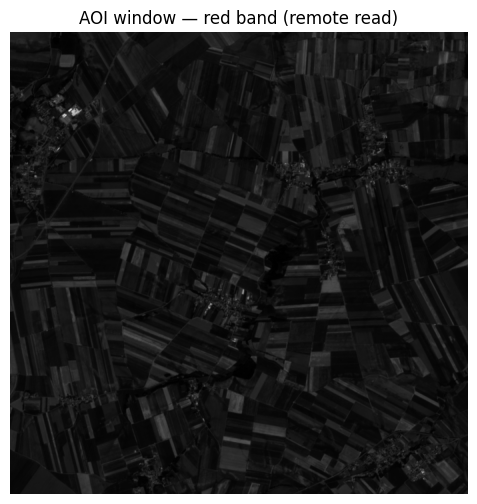

In [8]:
import pyproj

item = to_download[0]
href = item.assets["red"].href

with rasterio.open(href) as src:
    transformer = pyproj.Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    left, bottom = transformer.transform(BBOX[0], BBOX[1])
    right, top = transformer.transform(BBOX[2], BBOX[3])
    window = from_bounds(left, bottom, right, top, transform=src.transform)
    crop = src.read(1, window=window)
    print(f"Remote COG CRS: {src.crs}")
    print(f"Full tile: {src.width} x {src.height}")
    print(f"AOI window shape: {crop.shape}")

plt.figure(figsize=(6, 6))
plt.imshow(crop, cmap="gray")
plt.title("AOI window — red band (remote read)")
plt.axis("off")
plt.show()


## 8. Troubleshooting

| Problem | What to try |
|---|---|
| `Found 0 scenes` | Widen dates, raise `MAX_CLOUD`, check bbox order `[W, S, E, N]` |
| Slow downloads | Use fewer bands, `MAX_DOWNLOADS=1`, or windowed reads |
| `HTTP Error` / timeout | Re-run the download cell (it skips existing files) |

### Useful links
- Earth Search STAC: https://earth-search.aws.element84.com/v1
- Sentinel-2 mission description: https://sentiwiki.copernicus.eu/web/s2-mission

---
*Notebook purpose: hackathon onboarding for self-serve Sentinel-2 L2A downloads via Element 84.*
